# Machine Learning
## Course-End Project Problem Statement

# Employee Turnover Analytics

## Project Statement:

Portobello Tech is an app innovator who has devised an intelligent way of predicting employee turnover within the company. It periodically evaluates employees' work details, including the number of projects they worked on, average monthly working hours, time spent in the company, promotions in the last five years, and salary level.

Data from prior evaluations shows the employees’ satisfaction in the workplace. The data could be used to identify patterns in work style and their interest in continuing to work for the company.

The HR Department owns the data and uses it to predict employee turnover. Employee turnover refers to the total number of workers who leave a company over time.

As the ML Developer assigned to the HR Department, you have been asked to create ML programs to:

1. Perform data quality checks by checking for missing values, if any.
2. Understand what factors contributed most to employee turnover at EDA.
3. Perform clustering of employees who left based on their satisfaction and evaluation.
4. Handle the left Class Imbalance using the SMOTE technique.
5. Perform k-fold cross-validation model training and evaluate performance.
6. Identify the best model and justify the evaluation metrics used.
7. Suggest various retention strategies for targeted employees.

## Data will be modified from:

https://www.kaggle.com/liujiaqi/hr-comma-sepcsv

## Column Name / Description

| Column Name | Description |
|---|---|
| satisfaction_level | Satisfaction level at the job of an employee |
| last_evaluation | Rating between 0 and 1, received by an employee at his last evaluation |
| number_project | The number of projects an employee is involved in |
| average_montly_hours | Average number of hours in a month spent by an employee at the office |
| time_spend_company | Number of years spent in the company |
| Work_accident | 0 - no accident during employee stay, 1 - accident during employee stay |
| left | 0 indicates an employee stays with the company and 1 indicates an employee left the company |
| promotion_last_5years | Number of promotions in his stay |
| Department | Department to which an employee belongs to |
| salary | Salary in USD |

### 0. Imports

In [32]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering
from sklearn.cluster import KMeans

# Data preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Handling class imbalance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Cross-validation
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    recall_score,
    precision_score
)

## Perform the following steps:

### 1. Perform data quality checks by checking for missing values, if any.

Take an introductory look at the data:

In [ ]:
df = pd.read_csv("HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


Introductory column summary:

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


Examine quantity of duplicates rows, and then drop them.

In [35]:
# Check for duplicated rows
print("Number of duplicates:", df.duplicated().sum())
print("Original length:", len(df))

# Drop the duplicates
df = df.drop_duplicates()

print("New length:", len(df))

Number of duplicates: 3008
Original length: 14999
New length: 11991


We identified and removed 3,008 exact duplicate records, reducing the dataset from 14,999 to 11,991 observations.

Removing duplicates prevents identical observations from being disproportionately represented in statistical analyses and model training. However, this also changes the dataset distribution, potentially affecting the relative proportions of employees who stayed or left and other employee characteristics.

As the dataset does not contain unique employee identifiers, we assume that identical records represent redundant observations rather than distinct employees with coincidentally identical recorded attributes.

In [36]:
# Check percentage of null values
print(df.isna().mean() * 100)

satisfaction_level       0.0
last_evaluation          0.0
number_project           0.0
average_montly_hours     0.0
time_spend_company       0.0
Work_accident            0.0
left                     0.0
promotion_last_5years    0.0
sales                    0.0
salary                   0.0
dtype: float64


No missing values were found in the dataset. However, missing-value checks alone are insufficient to establish data quality. We will also examine categorical values, numerical ranges, and binary variables to identify potentially invalid observations.

In [37]:
# Examine data validity in categorical columns
categorical_cols = df.select_dtypes(include=[
    "category",
    "object",
    "str",
]).columns

for col in categorical_cols:
    print(df[col].value_counts())
    print()

sales
sales          3239
technical      2244
support        1821
IT              976
RandD           694
product_mng     686
marketing       673
accounting      621
hr              601
management      436
Name: count, dtype: int64

salary
low       5740
medium    5261
high       990
Name: count, dtype: int64



No unexpected categorical values have been observed.

In [38]:
# Examine the numerical columns which should contain only 0 or 1
conditional_cols = ["Work_accident", "left", "promotion_last_5years"]

for col in conditional_cols:
    print(df[col].value_counts())
    print()

Work_accident
0    10141
1     1850
Name: count, dtype: int64

left
0    10000
1     1991
Name: count, dtype: int64

promotion_last_5years
0    11788
1      203
Name: count, dtype: int64



No invalid values were identified in the selected columns.

In [39]:
# Confirm that "last_evaluation" is between 0 and 1, as the spec requires
print("Min >= 0\t", df["last_evaluation"].min() >= 0)
print("Max <= 1\t", df["last_evaluation"].max() <= 1)

Min >= 0	 True
Max <= 1	 True


`last_evaluation` is correctly between 0 and 1.

### 2. Understand what factors contributed most to employee turnover at EDA.

#### 2.1. Draw a heatmap of the correlation matrix between all numerical features or columns in the data.

A `correlation matrix` is a table that shows the correlation coefficients between multiple variables in a dataset.

A `heatmap` is a data visualization tool that uses color variations to show the magnitude of values across a two-dimensional grid or surface.

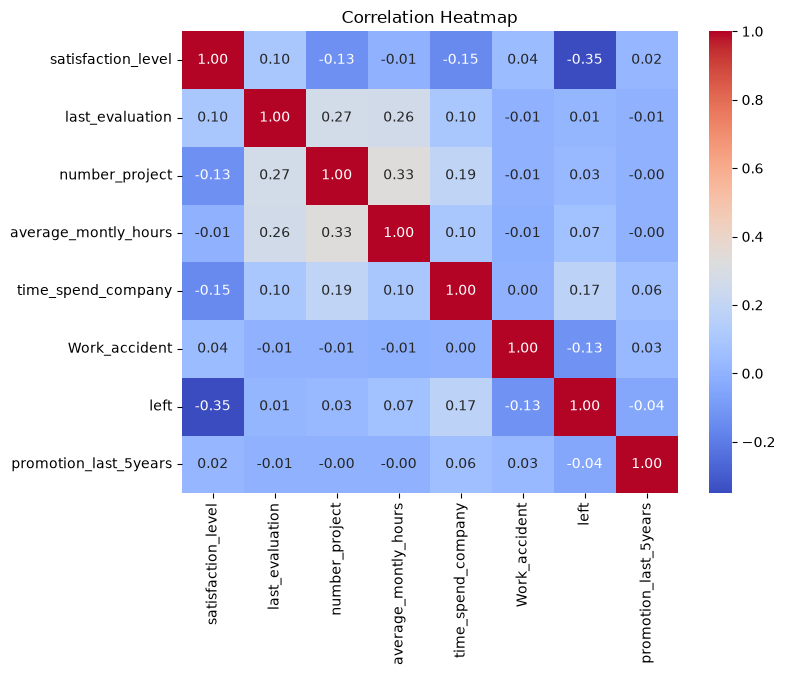

In [40]:
# Numerical columns only
numerical_cols = df.select_dtypes(include=[
    "number",
]).columns

correlation_matrix = df[numerical_cols].corr()

# Adjust length and width of the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Note that of particular interest for the problem statement is the "left" column. Below is an introductory examination of what factors are correlated with an employee leaving.

In [41]:
# Sort using absolute values to examine magnitudes
print(correlation_matrix["left"].abs().sort_values(ascending=False))

left                     1.000000
satisfaction_level       0.350558
time_spend_company       0.173295
Work_accident            0.125436
average_montly_hours     0.070409
promotion_last_5years    0.044657
number_project           0.030928
last_evaluation          0.013520
Name: left, dtype: float64


Three variables demonstrate relatively stronger correlations with employee turnover:
- `satisfaction_level`
- `time_spend_company`
- `Work_accident`

The correlation coefficients suggest that:
- Lower employee satisfaction is associated with a higher likelihood of turnover.
- Longer tenure is associated with a higher likelihood of turnover.
- Employees with recorded workplace accidents exhibit a lower observed turnover rate.

These relationships are relatively modest, with employee satisfaction demonstrating the strongest correlation. Further investigation is necessary to understand the underlying relationships. Correlation alone does not establish causation.

#### 2.2. Draw the distribution plot of:

- Employee Satisfaction (use column satisfaction_level)
- Employee Evaluation (use column last_evaluation)
- Employee Average Monthly Hours (use column average_montly_hours)

A `distribution plot` is a data visualization that shows how data values are spread out across a range.

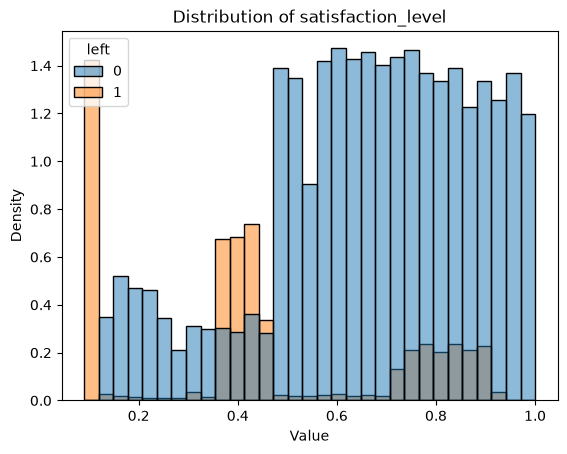

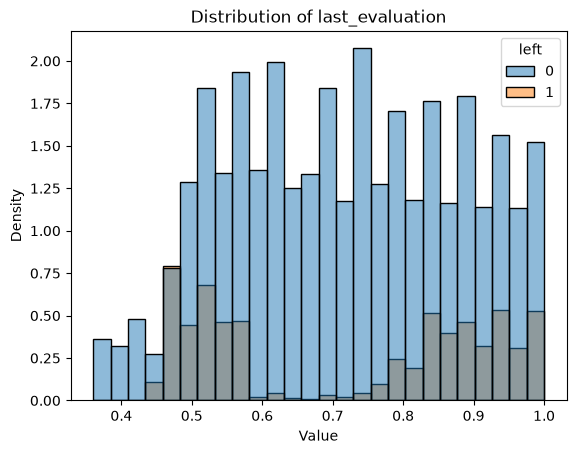

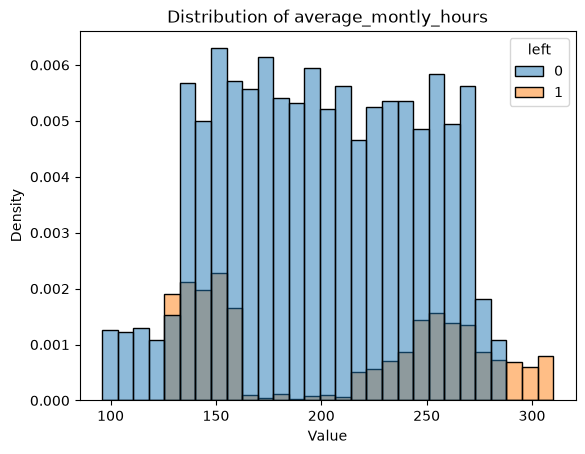

In [42]:
target_cols = [
    "satisfaction_level",
    "last_evaluation",
    "average_montly_hours"
]

for col in target_cols:
    sns.histplot(
        data=df,
        x=col,
        hue="left",  # Color the bars by turnover status
        stat="density"  # Useful for comparing distributions
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Value")
    plt.ylabel("Density")
    plt.show()

Some observations can be made from the visualizations:

Using `satisfaction_level`:
- Most employees who left had a satisfaction score under 0.5.

Using `last_evaluation`:
- Most employees who left had a performance evaluation score either under 0.6 or above 0.8. Interestingly, this indicates that employees who left have either lower or higher evaluation scores. Further examination will be required for why high-performing employees left.

Using `average_montly_hours`:
- Employees who left appear to be concentrated toward both lower and higher ranges of average monthly working hours. This may indicate that unusually low or high workloads are associated with turnover. Further investigation would be necessary to determine whether workload contributes to employee dissatisfaction or departure.


#### 2.3. Draw the bar plot of the employee project count of both employees who left and stayed in the organization (use column `number_project` and hue column `left`), and give your inferences from the plot.

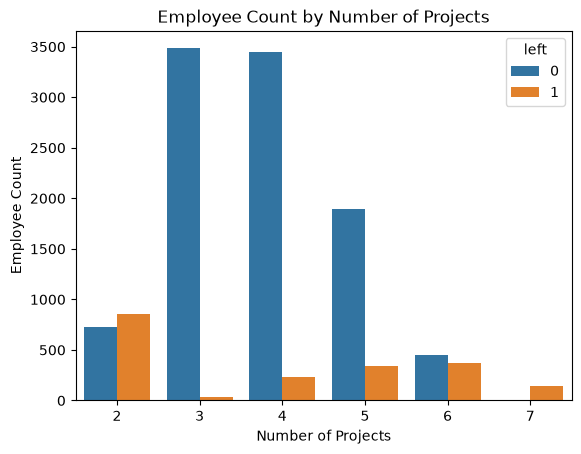

In [43]:
sns.countplot(
    data=df,
    x="number_project",
    hue="left"
)

plt.title("Employee Count by Number of Projects")
plt.xlabel("Number of Projects")
plt.ylabel("Employee Count")
plt.show()

Employees who left appear disproportionately represented among those assigned relatively few projects (two) or a relatively high number of projects (six or more).

Employees assigned three to five projects demonstrate comparatively lower turnover.

This suggests that workload distribution may be associated with employee retention. Both insufficient engagement and excessive workload could potentially contribute to employee dissatisfaction.

### 3. Perform clustering of employees who left based on their satisfaction and evaluation.

#### 3.1. Choose columns `satisfaction_level`, `last_evaluation`, and `left`.

In [44]:
# Select relevant columns
df_cluster = df[["satisfaction_level", "last_evaluation", "left"]]
display(df_cluster.head())

,satisfaction_level,last_evaluation,left
0,0.38,0.53,1
1,0.80,0.86,1
2,0.11,0.88,1
3,0.72,0.87,1
4,0.37,0.52,1


#### 3.2. Do K-means clustering of employees who left the company into 3 clusters.

K-Means divides the data into a chosen number of clusters, written as $k$. It uses a centroid for each cluster. A centroid is the mean position of the points assigned to that cluster.

In [45]:
# Filter employees who left
df_cluster = df_cluster[df_cluster["left"] == 1].copy()

# Keep only clustering features
X = df_cluster[["satisfaction_level", "last_evaluation"]]

# Initialize K-means
kmeans = KMeans(
    n_clusters=3,
    random_state=123,
    n_init=10
)

# Fit the model and assign cluster labels
df_cluster["Cluster"] = kmeans.fit_predict(X)

# Quick look at the DataFrame
df_cluster.head()

,satisfaction_level,last_evaluation,left,Cluster
0,0.38,0.53,1,2
1,0.80,0.86,1,1
2,0.11,0.88,1,0
3,0.72,0.87,1,1
4,0.37,0.52,1,2


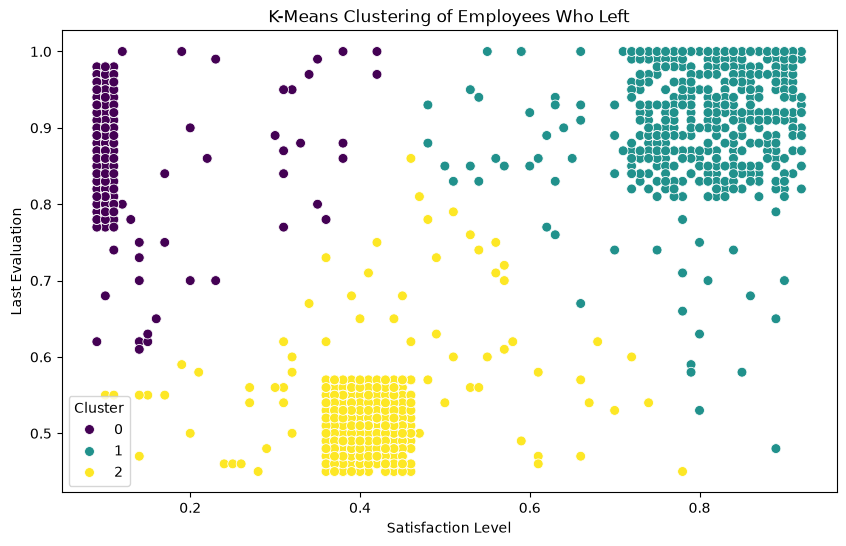

In [46]:
# Visualize the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x="satisfaction_level",
    y="last_evaluation",
    hue="Cluster",
    palette="viridis",
    s=50
)

plt.title("K-Means Clustering of Employees Who Left")
plt.xlabel("Satisfaction Level")
plt.ylabel("Last Evaluation")
plt.show()

In [47]:
# Examine the mean characteristics of each cluster
cluster_summary = df_cluster.groupby("Cluster")[
    ["satisfaction_level", "last_evaluation"]
].mean().round(3)

cluster_summary

,satisfaction_level,last_evaluation
Cluster,,
0,0.111,0.869
1,0.806,0.913
2,0.410,0.517


#### 3.3. Based on the satisfaction and evaluation factors, give your thoughts on the employee clusters.

Three distinct employee groups emerge from the clustering analysis:

**Cluster 0 — Low satisfaction, high evaluation**

These employees demonstrated relatively strong performance despite reporting very low satisfaction. This group warrants particular attention because high performance does not necessarily translate into employee satisfaction or retention.

**Cluster 1 — High satisfaction, high evaluation**

These employees demonstrated both high satisfaction and strong performance but nevertheless left the company. This suggests that satisfaction and performance alone cannot fully explain employee turnover. Other factors, such as compensation, career opportunities, or personal circumstances, may also be relevant.

**Cluster 2 — Moderate-low satisfaction, low evaluation**

These employees demonstrated relatively low satisfaction and lower performance evaluations. Further investigation could help determine whether workload, management support, or other workplace factors contributed to their experiences.

### 4. Handle the `left` Class Imbalance using the SMOTE technique.

#### 4.1. Pre-process the data by converting categorical columns to numerical columns by:

- Separating categorical variables and numeric variables
- Applying `get_dummies()` to the categorical variables
- Combining categorical variables and numeric variables

In [48]:
# Apply get_dummies() to the categorical columns
# This will convert the values to 0/1 representations of themselves
df_dum = pd.get_dummies(
    df[categorical_cols],
    dtype=int
)

# Examine the transformation
df_dum.head()

,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0,0,0,0,0,0,0,1,0,0,0,1,0


In [49]:
# Combine the categorical and numerical columns
df_final = pd.concat([df[numerical_cols], df_dum], axis=1)
df_final.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0


#### 4.2. Do the stratified split of the dataset to train and test in the ratio 80:20 with random_state=123.

The goal here is to create an 80% training set and a 20% testing set.

From the 80% training set we acquire:
- `X_train`
- `y_train`

The model is trained by using these two values.

From the 20% testing set we acquire:
- `X_test`
- `y_test`

We will use `X_test` to predict the values of `y_test` with the trained model. We compare the predicted values to `y_test` to determine how well the model performs.

`stratify=y` helps preserve the class proportions in both sets. `random_state=123` makes the split reproducible.

In [50]:
# Need to predict "left" so will drop it here
X = df_final.drop("left", axis=1)
y = df_final["left"]

# "stratify" will maintain class proportions in both sets
# Same proportion of employees who stayed and who left
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=123,
    stratify=y
)

# Check for maintained class proportions
print("Training set:")
print(y_train.value_counts(normalize=True))

print("\nTesting set:")
print(y_test.value_counts(normalize=True))

Training set:
left
0    0.833924
1    0.166076
Name: proportion, dtype: float64

Testing set:
left
0    0.834098
1    0.165902
Name: proportion, dtype: float64


#### 4.3. Upsample the train dataset using the SMOTE technique from the imblearn module.

SMOTE (Synthetic Minority Over-sampling Technique) addresses class imbalance by generating synthetic observations for the minority class. In this project, it increases the representation of employees who left the company, helping the models learn patterns associated with turnover.

In [51]:
smote = SMOTE(random_state=123)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts().sort_index())

print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

Before SMOTE:
left
0    7999
1    1593
Name: count, dtype: int64
After SMOTE:
left
0    7999
1    7999
Name: count, dtype: int64


### 5. Perform 5-fold cross-validation model training and evaluate performance 

- 5.1. Train a logistic regression model, apply a 5-fold CV, and plot the classification report.
- 5.2. Train a Random Forest Classifier model, apply the 5-fold CV, and plot the classification report.
- 5.3. Train a Gradient Boosting Classifier model, apply the 5-fold CV, and plot the classification report.

**Note:** All three will be addressed in the loop of the below cell.

**K-fold cross-validation**  divides the training data into several parts called folds. The model trains on some parts and is evaluated on another, repeating the process across different splits. This produces several useful metrics, which can then be averaged. **Stratified folds** keep the class proportions approximately consistent.

Three classification models will be evaluated here:

- `Logistic Regression` - Estimates the probability that an observation belongs to a particular class using a logistic function.
- `Random Forest` - Trains multiple decision trees and combines their predictions. Instead of relying on a single tree, the forest uses the votes of many trees.
- `Gradient Boosting` - Adds models one at a time. Each successive model attempts to correct the errors made by the existing ensemble. The contributions of these models are controlled by a learning rate.

In [52]:
def get_model_name(in_model):
    """Get the name of the model, e.g. 'LogisticRegression'."""
    return type(in_model).__name__


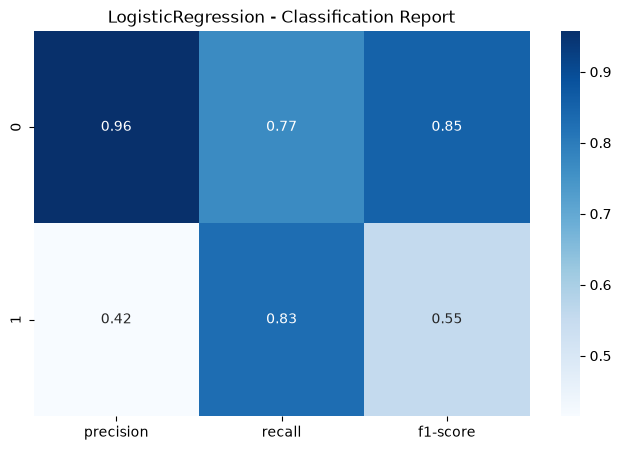

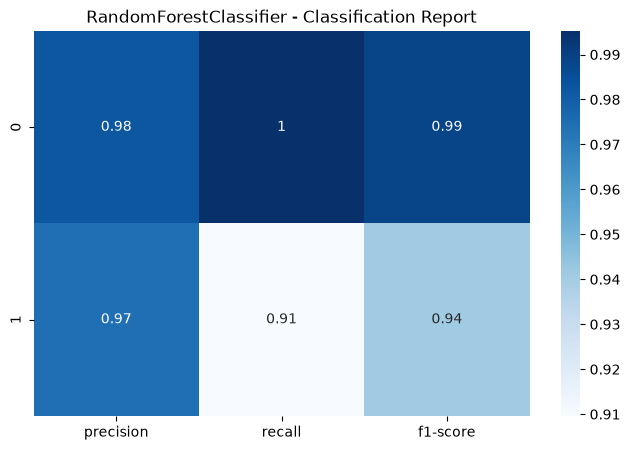

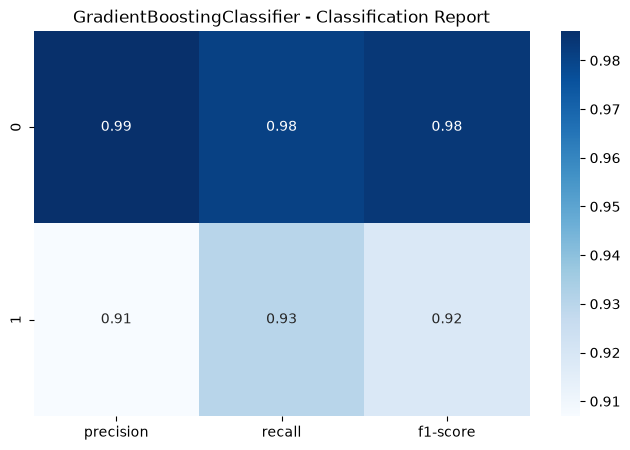

In [53]:
# Address 5.1, 5.2, and 5.3 in one loop

# The three target models
models = [
    LogisticRegression(max_iter=1000, random_state=123),
    RandomForestClassifier(
        n_estimators=100,
        random_state=123
    ),
    GradientBoostingClassifier(random_state=123)
]

# Map model to predicted values, for later
model_to_pred = []

for model in models:
    # Pipeline to make sure that SMOTE is applied in each fold
    # Also apply feature scaling as LogisticRegression is sensitive
    # Note: The other two do not need scaling, but we will do so for simplicity
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=123)),
        ("model", model)
    ])

    # Apply a five-fold cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    # Collect the combined predictions from the five folds
    y_pred = cross_val_predict(
        pipeline, X_train, y_train, cv=cv
    )

    # Generate the report values
    report = classification_report(
        y_train, y_pred, output_dict=True
    )

    # Transpose to get precision, recall, f1-score on the bottom axis
    report_df = pd.DataFrame(report).transpose()

    # Get the name of the model, e.g. "LogisticRegression"
    model_name = get_model_name(model)

    # Save the predictions for later analysis
    model_to_pred.append((model_name, y_pred))

    plt.figure(figsize=(8, 5))

    # Select first two rows, first three columns
    # (Other rows contain accuracy, macro avg, and weighted avg)
    sns.heatmap(report_df.iloc[0:2, 0:3], annot=True, cmap="Blues")
    plt.title(f"{model_name} - Classification Report")
    plt.show()

### 6. Identify the best model and justify the evaluation metrics used.

#### 6.1. Find the ROC/AUC for each model and plot the ROC curve.

ROC is the Receiver Operating Characteristic. It is a curve showing the relationship between:
- True Positive Rate (Recall)
- False Positive Rate

AUC is the Area Under the Curve. It measures how well a model distinguishes between employees who left and employees who stayed. A higher AUC indicates a better ability to distinguish between the two classes.

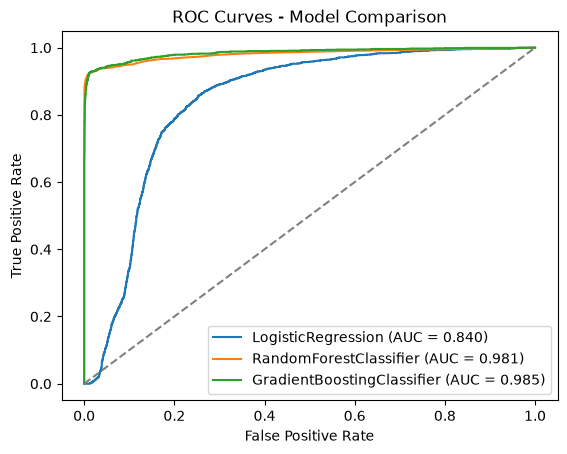

In [54]:
for model in models:
    # Put together the pipeline again
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=123)),
        ("model", model)
    ])

    # We want predicted probabilities rather than predicted class labels
    # "predict_proba" acquires the probability that each employee belongs to
    # each class
    # It returns two probabilities for each employee
    # [:, 1] selects all rows of Column 1 --> Probability of leaving
    y_prob = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]

    # Calculate ROC curves
    fpr, tpr, _ = roc_curve(y_train, y_prob)

    # Calculate AUC scores
    auc = roc_auc_score(y_train, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{get_model_name(model)} (AUC = {auc:.3f})"
    )

# Reference line for random guessing
# Models should perform well above this line
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.show()

**Score Interpretation:**

A model with a ROC curve closer to the top-left corner generally demonstrates better classification performance across different decision thresholds. A higher AUC indicates stronger overall discrimination between the two classes.

In this case, the `GradientBoostingClassifier` model has performed the best out of the three selected. It has the highest AUC score $(AUC = 0.985)$.

However, given that this model is close to `RandomForestClassifier`, it will be useful to examine the confusion matrices before making a final model selection.

#### 6.2. Find the confusion matrix for each of the models.

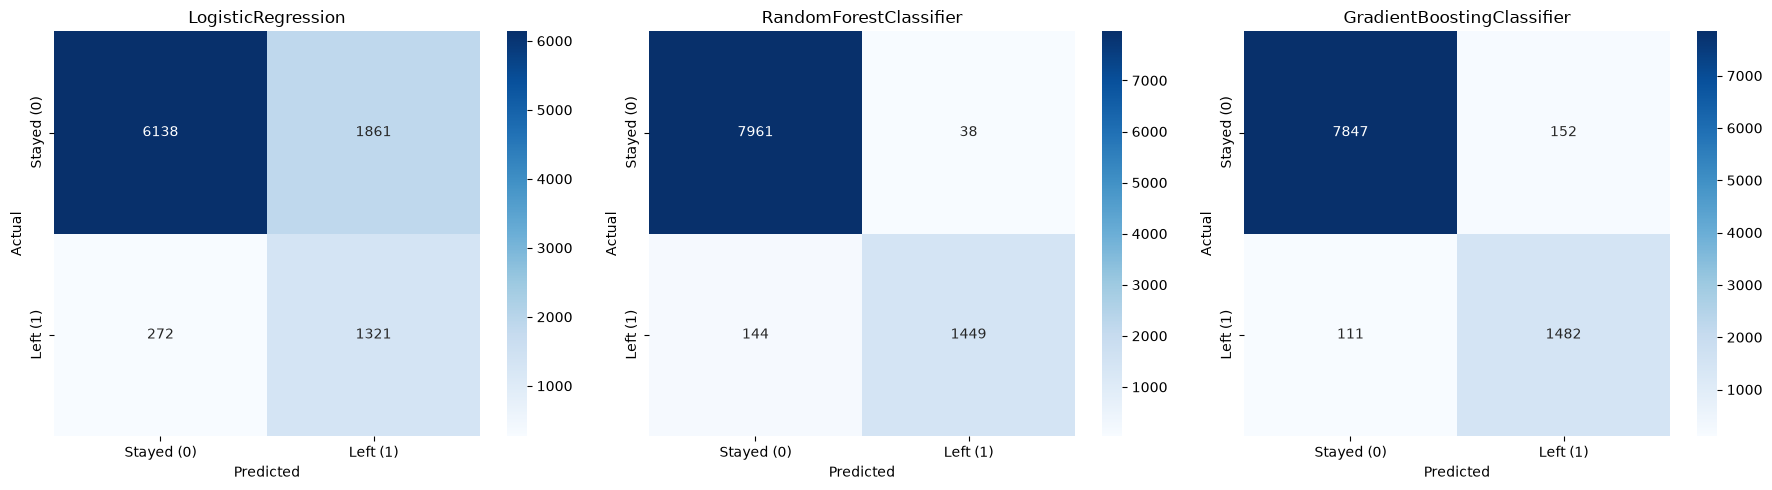

In [55]:
# Plot all three matrices next to each other
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Iterate through both the axis objects and the model-to-pred listings
for ax, (model_name, pred) in zip(axes, model_to_pred):
    cm = confusion_matrix(y_train, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(["Stayed (0)", "Left (1)"])
    ax.set_yticklabels(["Stayed (0)", "Left (1)"])

plt.tight_layout()
plt.show()


Excellent performance is seen from `RandomForestClassifier`. It correctly identifies:
- 7961 employees who stayed
- 1449 employees who left

It only missed:
- 144 employees who left but were predicted to stay (false negatives)
- 38 employees who stayed but were predicted to leave (false positives)

Interestingly, it also performs slightly better than `GradientBoostingClassifier`:
- RandomForestClassifier missed 182 values
- GradientBoostingClassifier missed 263 values

#### 6.3. Explain which metric needs to be used from the confusion matrix: Recall or Precision?

**Recall** measures how many employees who actually left were correctly identified. In this project, high Recall means that the company successfully identifies most employees who are at risk of leaving.

**Precision** measures how many employees predicted to leave actually left. In this project, high Precision means that the company avoids unnecessarily targeting employees who would have stayed.

Recall will be prioritized for identifying employees at risk of departure.

Consider the consequences:
- Low Recall: The company misses employees who are actually going to leave. This represents a missed opportunity for employee retention.
- Low Precision: The company targets some employees who would have stayed anyway. This results in potentially unnecessary retention efforts.

Missing an employee who is about to leave can be more costly than unnecessarily offering support to an employee who would have stayed.

**Note:** Although Recall is prioritized in this project, Precision should not be disregarded. A company has limited resources for retention initiatives, and unnecessarily targeting large numbers of employees could increase costs. The appropriate balance between Recall and Precision ultimately depends on the business objectives and the cost associated with each type of classification error.

Let us examine the Recall and Precision of the tested models:

In [56]:
scores = []
for model_name, pred in model_to_pred:
    # pos_label=1 because 1 represents employees who left
    recall = recall_score(y_train, pred, pos_label=1)
    precision = precision_score(y_train, pred, pos_label=1)

    scores.append({
        "model": model_name,
        "recall": recall,
        "precision": precision,
    })

pd.DataFrame(scores).round(3).transpose()

,0,1,2
model,LogisticRegression,RandomForestClassifier,GradientBoostingClassifier
recall,0.829,0.91,0.93
precision,0.415,0.974,0.907


Although Recall is prioritized because failing to identify departing employees can result in missed retention opportunities, Precision must also be considered to avoid unnecessary interventions.

Gradient Boosting achieves slightly higher Recall (93.0% versus 91.0%), while Random Forest achieves substantially higher Precision (97.4% versus 90.7%). Random Forest also produces fewer total classification errors.

Therefore, `Random Forest` will be selected as the preferred model because it provides a favorable balance between identifying employees who leave and minimizing false positives. This selection assumes that the additional cost of unnecessary interventions is meaningful relative to the cost of missed departures.

### 7. Suggest various retention strategies for targeted employees.

#### 7.1. Using the best model, predict the probability of employee turnover in the test data.

In [57]:
# Random Forest has been selected due to its demonstrated high performance
pipeline_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=123)),
    ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=123
        ),
    )
])

# Train Random Forest pipeline
pipeline_rf.fit(X_train, y_train)

# Predict employee turnover on the unseen test data
y_pred_test = pipeline_rf.predict(X_test)

# Predict probabilities on test data
# [:, 1] means probability of an employee leaving
y_prob_test = pipeline_rf.predict_proba(X_test)[:, 1]

**Note:** SMOTE is not applied to X_test. The original distribution must be maintained so that the evaluation reflects real-world data.

Let us examine how well the final model performed:

In [58]:
# Classification metrics
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2001
           1       0.97      0.90      0.93       398

    accuracy                           0.98      2399
   macro avg       0.98      0.95      0.96      2399
weighted avg       0.98      0.98      0.98      2399



A `precision` score of 97% indicates that 97% of the employees predicted to leave by the model actually left.

A `recall` score of 90% indicates that the model identified 90% of the employees who actually left.

In [59]:
# ROC-AUC
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob_test))

Test ROC-AUC: 0.9749252258292963


A `ROC-AUC` score of 97.5% indicates how well the model distinguished employees who left from those who stayed.

The test ROC-AUC of 0.975 is comparable to the cross-validation RandomForest ROC-AUC of 0.981. This suggests that the model maintains similar discriminatory performance on unseen data. However, further validation on data collected from different time periods or employee populations would provide stronger evidence of generalizability.

[Text(0, 0.5, 'Stayed (0)'), Text(0, 1.5, 'Left (1)')]

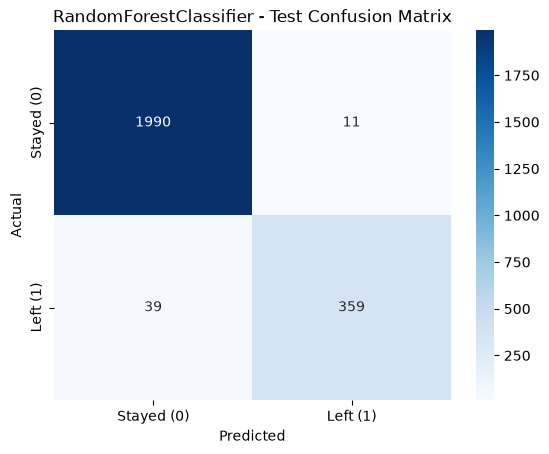

In [60]:
# Confusion matrix
fig, ax = plt.subplots()

sns.heatmap(
    confusion_matrix(y_test, y_pred_test),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax
)
ax.set_title("RandomForestClassifier - Test Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticklabels(["Stayed (0)", "Left (1)"])
ax.set_yticklabels(["Stayed (0)", "Left (1)"])

The `RandomForestClassifier` correctly identified:
- 1990 employees who stayed
- 359 employees who left

It only missed:
- 39 employees who left but were predicted to stay (false negatives)
- 11 employees who stayed but were predicted to leave (false positives)

Let us examine how the model rated the importance of each feature when it comes to employees leaving:

In [61]:
feature_importance = pd.Series(
    pipeline_rf.named_steps["model"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(5)

time_spend_company      0.263417
satisfaction_level      0.245517
number_project          0.172548
average_montly_hours    0.136982
last_evaluation         0.123889
dtype: float64

The Random Forest model identifies the following features as having the greatest relative importance in its predictions:
- Time spent at the company
- Employee satisfaction level
- Number of projects

These variables appear to provide substantial predictive information when identifying employees who leave. However, feature importance indicates predictive contribution rather than causation. Further analysis would be necessary to establish the underlying reasons for employee turnover.

#### 7.2. Based on the probability score range below, categorize the employees into four zones and suggest your thoughts on the retention strategies for each zone.

- Safe Zone (Green) (Score < 20%)
- Low-Risk Zone (Yellow) (20% < Score < 60%)
- Medium-Risk Zone (Orange) (60% < Score < 90%)
- High-Risk Zone (Red) (Score > 90%).

In [62]:
# Create results DataFrame
turnover_predictions = pd.DataFrame({
    "Actual": y_test,
    "Turnover_Probability": y_prob_test
})

# Establish bins as per the given score range
# nextafter() here gets the smallest number bigger than 1 in direction of 2
# Otherwise values of exactly 1 would be missed
bins = [0, 0.20, 0.60, 0.90, np.nextafter(1.0, 2.0)]

# Describe labels as per the given categories
labels = [
    "Safe (Green)",
    "Low-Risk (Yellow)",
    "Medium-Risk (Orange)",
    "High-Risk (Red)"
]

# Divide the data into the target bins
turnover_predictions["Risk_Zone"] = pd.cut(
    turnover_predictions["Turnover_Probability"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False  # Keep the right-most edge goes to left bin
)

# Count employees in each risk zone
zone_counts = turnover_predictions["Risk_Zone"].value_counts()
    
# Examine the data distribution
print(zone_counts)

Risk_Zone
Safe (Green)            1927
High-Risk (Red)          333
Low-Risk (Yellow)        106
Medium-Risk (Orange)      33
Name: count, dtype: int64


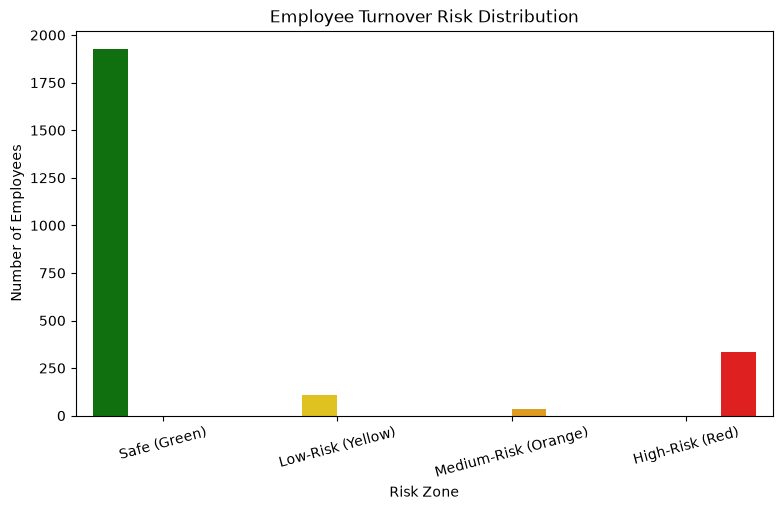

In [63]:
colors = ["green", "gold", "orange", "red"]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=zone_counts.index,
    y=zone_counts.values,
    hue=zone_counts.index,
    palette=colors,
    legend=False
)

plt.title("Employee Turnover Risk Distribution")
plt.xlabel("Risk Zone")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.show()

**Retention Strategies for each Zone**

1. Safe Zone (Green) – Below 20%
   - Maintain a positive work environment and employee engagement
   - Recognize achievements through rewards and appreciation programs
   - Provide opportunities for professional development and career advancement
   - Continue monitoring employee satisfaction through periodic surveys

2. Low-Risk Zone (Yellow) – 20%–60%
   - Conduct regular one-on-one meetings to identify potential concerns
   - Monitor workload and ensure a healthy work-life balance
   - Provide constructive feedback and address employee concerns
   - Identify opportunities for additional training and career growth

3. Medium-Risk Zone (Orange) – 60%–90%
   - Conduct targeted discussions to understand employee dissatisfaction
   - Review compensation, workload, and opportunities for promotion
   - Develop individualized career development and improvement plans
   - Address workplace issues before they lead to employee departure

4. High-Risk Zone (Red) – Above 90%
   - Prioritize immediate one-on-one retention discussions
   - Identify and address the primary reasons for considering departure
   - Explore compensation adjustments, promotions, or role changes where appropriate
   - Develop personalized retention plans and establish follow-up meetings

Retention interventions should also consider the underlying characteristics contributing to an employee's predicted turnover risk. For example, employees with high project workloads may benefit from workload redistribution, while high-performing employees with low satisfaction may benefit from career development opportunities, recognition, or compensation reviews.

The predicted risk score should be used as an indicator for further investigation rather than as a definitive assessment of an employee's intention to leave.
